Class distribution:
  class 0: 684 (50.0%)
  class 1: 683 (50.0%)

Split sizes → train: 1093, test: 274

=== Baseline Results (LogReg + TF-IDF) ===
Accuracy: 0.5620
Precision (AI=1): 0.5570
Recall    (AI=1): 0.6058
F1        (AI=1): 0.5804
ROC-AUC: 0.5506

Classification report:
              precision    recall  f1-score   support

           0     0.5680    0.5182    0.5420       137
           1     0.5570    0.6058    0.5804       137

    accuracy                         0.5620       274
   macro avg     0.5625    0.5620    0.5612       274
weighted avg     0.5625    0.5620    0.5612       274



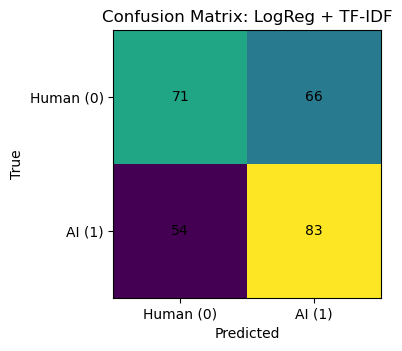

In [1]:
# Baseline: AI vs Human Text (Logistic Regression + TF-IDF)
# ---------------------------------------------------------
# Quick start:
#   pip install pandas scikit-learn matplotlib
#
# Notes:
# - Adjust CSV_PATH if your file lives elsewhere.
# - Uses text column: "text_content" and label column: "label".

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, roc_auc_score
)
import matplotlib.pyplot as plt

RNG = 42

# 1) Load data
CSV_PATH = r"C:\Users\xhani\Downloads\ai_human_content_detection_dataset.csv"  # <-- change if needed
TEXT_COL = "text_content"
LABEL_COL = "label"

df = pd.read_csv(CSV_PATH, encoding="utf-8")
df = df[[TEXT_COL, LABEL_COL]].dropna()
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df[LABEL_COL] = df[LABEL_COL].astype(int)

X = df[TEXT_COL].values
y = df[LABEL_COL].values

# Quick class balance check
unique, counts = np.unique(y, return_counts=True)
print("Class distribution:")
for u, c in zip(unique, counts):
    print(f"  class {u}: {c} ({c/len(y):.1%})")

# 2) Split (80/20) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RNG
)

print(f"\nSplit sizes → train: {len(X_train)}, test: {len(X_test)}")

# 3) TF-IDF vectorization (unigrams + bigrams)
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    stop_words="english"
)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf  = vectorizer.transform(X_test)

# 4) Logistic Regression (balanced to handle any skew)
clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    solver="liblinear",
    random_state=RNG
)
clf.fit(X_train_tfidf, y_train)

# 5) Evaluate
y_pred = clf.predict(X_test_tfidf)

# If available, compute ROC-AUC using predict_proba
roc_auc = None
if hasattr(clf, "predict_proba"):
    proba = clf.predict_proba(X_test_tfidf)[:, 1]
    roc_auc = roc_auc_score(y_test, proba)

acc = accuracy_score(y_test, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average="binary", zero_division=0
)

print("\n=== Baseline Results (LogReg + TF-IDF) ===")
print(f"Accuracy: {acc:.4f}")
print(f"Precision (AI=1): {prec:.4f}")
print(f"Recall    (AI=1): {rec:.4f}")
print(f"F1        (AI=1): {f1:.4f}")
if roc_auc is not None:
    print(f"ROC-AUC: {roc_auc:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4))

# 6) Confusion matrix (matplotlib only)
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Confusion Matrix: LogReg + TF-IDF")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
# Tick labels for binary classes 0/1
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Human (0)", "AI (1)"])
ax.set_yticklabels(["Human (0)", "AI (1)"])
# Write counts
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha="center", va="center")

plt.tight_layout()
plt.show()


In [2]:
print("Length of text 0:", len(df.loc[0, "text_content"].split()))
print("Preview:", df.loc[0, "text_content"][:200])


Length of text 0: 288
Preview: Score each cause. Quality throughout beautiful instead.
Despite measure ago current.
Determine operation speak according south recently. Everyone democratic shake bill here grow. Page southern role mo
